# Autoregressive (AR) Models

An AR($p$) model $X_t=c+\sum\phi_jX_{t-j}+\varepsilon_t$ is stationary and causal when the roots of $\phi(z)=1-\phi_1z-\dots-\phi_pz^p$ lie outside the unit circle. This notebook checks the AR(1) and AR(2) moments by hand, simulates data, estimates parameters by conditional least squares, and examines forecasts.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.ar_model import AutoReg, ar_select_order

rng = np.random.default_rng(40)

# AR(1) numbers from the note: y_t = 1 + 0.8 y_{t-1} + e_t, Var(e)=1
c, phi = 1.0, 0.8
mu = c / (1 - phi)
var = 1 / (1 - phi**2)
print("mean:", mu, " variance:", round(var, 4))
print("forecast deviations h=1,5:", 0.8 * 2, round(0.8**5 * 2, 4))

# AR(2) roots from the note: y_t = 0.6 y_{t-1} - 0.2 y_{t-2} + e_t
poly_roots = np.roots([0.2, -0.6, 1.0])            # 1 - 0.6 z + 0.2 z^2
print("AR polynomial root moduli:", np.round(np.abs(poly_roots), 3), "(outside unit circle -> stationary)")
print("recursion root moduli    :", np.round(np.abs(np.roots([1, -0.6, 0.2])), 3))

mean: 5.000000000000001  variance: 2.7778
forecast deviations h=1,5: 1.6 0.6554
AR polynomial root moduli: [2.236 2.236] (outside unit circle -> stationary)
recursion root moduli    : [0.447 0.447]


The polynomial roots (modulus $\sqrt5\approx2.236$) are the reciprocals of the characteristic-equation roots (modulus $\approx0.447$): the two conventions give opposite inside/outside statements but the same conclusion.

sample mean / var: 4.941 2.798  (theory 5 / 2.778)


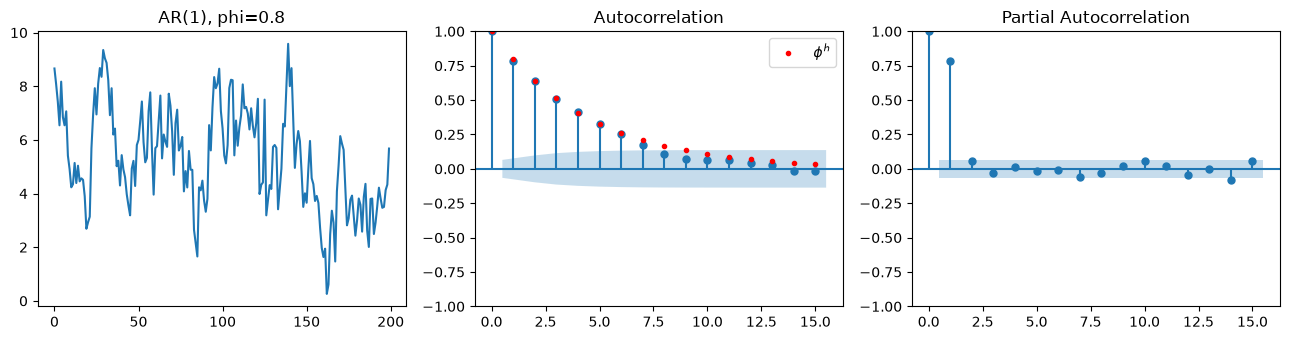

In [2]:
n = 1000
x = np.zeros(n)
for t in range(1, n):
    x[t] = c + phi * x[t - 1] + rng.normal()
x = x[100:]
print("sample mean / var:", x.mean().round(3), x.var().round(3), " (theory 5 / 2.778)")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
ax[0].plot(x[:200]); ax[0].set_title("AR(1), phi=0.8")
plot_acf(x, lags=15, ax=ax[1]); plot_pacf(x, lags=15, ax=ax[2], method="ywm")
ax[1].plot(range(16), 0.8 ** np.arange(16), "r.", label=r"$\phi^h$"); ax[1].legend()
plt.tight_layout(); plt.show()

The ACF decays like $0.8^h$ while the PACF cuts off after lag 1 — the standard AR(1) identification pattern.

In [3]:
# Conditional least squares by hand: regress x_t on (1, x_{t-1})
y = x[1:]
X = np.column_stack([np.ones(len(y)), x[:-1]])
beta = np.linalg.solve(X.T @ X, X.T @ y)
print("hand OLS (c, phi):", beta.round(4))

res = AutoReg(x, lags=1, trend="c").fit()
print("AutoReg          :", res.params.round(4))
print("implied mean c/(1-phi):", round(beta[0] / (1 - beta[1]), 3))

hand OLS (c, phi): [1.0441 0.7875]
AutoReg          : [1.0441 0.7875]
implied mean c/(1-phi): 4.914


Because the regressors are observed lagged values, OLS applies directly to AR models (unlike MA models); note the intercept is $c$, not the process mean $c/(1-\phi)$.

In [4]:
# Order selection with AIC/BIC on an AR(2) series
z = np.zeros(1500)
for t in range(2, len(z)):
    z[t] = 0.6 * z[t - 1] - 0.3 * z[t - 2] + rng.normal()
sel = ar_select_order(z, maxlag=6, ic="aic", trend="n")
print("AIC chooses lags:", sel.ar_lags)
for p in range(1, 5):
    r = AutoReg(z, lags=p, trend="n", hold_back=4).fit()   # same sample for every p
    print(f"AR({p}): AIC={r.aic:7.3f} BIC={r.bic:7.3f}")

AIC chooses lags: [1, 2]
AR(1): AIC=4399.679 BIC=4410.300
AR(2): AIC=4289.545 BIC=4305.477
AR(3): AIC=4289.722 BIC=4310.964
AR(4): AIC=4290.780 BIC=4317.332


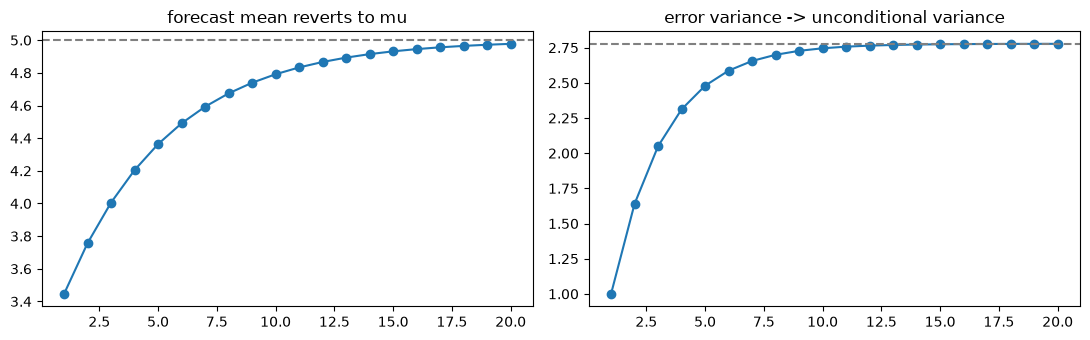

In [5]:
# Forecast uncertainty for the AR(1): variance sigma^2 * sum phi^{2j}
h = np.arange(1, 21)
fvar = (1 - phi ** (2 * h)) / (1 - phi**2)
fmean = mu + phi**h * (x[-1] - mu)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(h, fmean, "o-"); ax[0].axhline(mu, ls="--", c="gray"); ax[0].set_title("forecast mean reverts to mu")
ax[1].plot(h, fvar, "o-"); ax[1].axhline(var, ls="--", c="gray"); ax[1].set_title("error variance -> unconditional variance")
plt.tight_layout(); plt.show()

The point forecast converges to $\mu=5$ and the forecast-error variance climbs to $\sigma^2/(1-\phi^2)=2.78$: far-horizon forecasts carry no more information than the unconditional distribution.